Train Time: 1.2758s | Final Train Loss: 0.5100 | Final Test Loss: 0.5319
Test Accuracy: 0.7175 | Test F1: 0.7088


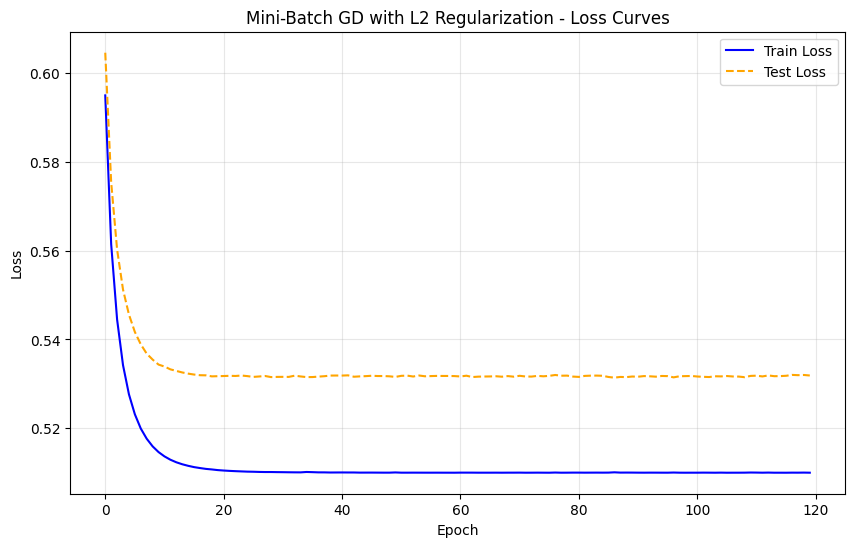

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# 1. توليد البيانات
X, y = make_classification(
    n_samples=4000, n_features=12, n_informative=8, n_redundant=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. تقييس الميزات
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# دالة الـ Sigmoid
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

# دالة الخسارة (Binary Cross-Entropy) مع دعم التنظيم L2
def bce_loss(y_true, y_prob, w=None, l2_lambda=0.0):
    y_prob = np.clip(y_prob, 1e-12, 1.0 - 1e-12)
    loss = -np.mean(y_true * np.log(y_prob) + (1.0 - y_true) * np.log(1.0 - y_prob))
    if w is not None and l2_lambda > 0:
        loss += (l2_lambda / (2 * len(y_true))) * np.sum(w ** 2)
    return loss

# 3. إعداد المعاملات الفائقة
rng = np.random.default_rng(42)
w = np.zeros(X_train.shape[1])
b = 0.0
lr = 0.05
batch_size = 64
epochs = 120
l2_lambda = 0.1  # معامل تنظيم L2 لمنع Overfitting

train_losses = []
test_losses = []

t0 = time.perf_counter()
for _ in range(epochs):
    idx = rng.permutation(len(y_train))
    for start in range(0, len(y_train), batch_size):
        batch = idx[start : start + batch_size]
        Xb, yb = X_train[batch], y_train[batch]

        # التنبؤ وحساب الخطأ
        err = sigmoid(Xb @ w + b) - yb

        # حساب المشتقات مع إضافة مشتقة تنظيم L2 للوزن w
        dw = (Xb.T @ err) / len(yb) + (l2_lambda / len(yb)) * w
        db = np.mean(err)

        # تحديث الأوزان والانحياز
        w -= lr * dw
        b -= lr * db

    # تسجيل الخسارة لكل حقبة
    train_losses.append(bce_loss(y_train, sigmoid(X_train @ w + b), w, l2_lambda))
    test_losses.append(bce_loss(y_test, sigmoid(X_test @ w + b), w, l2_lambda))

train_time = time.perf_counter() - t0

# 4. التقييم على بيانات الاختبار
test_preds = (sigmoid(X_test @ w + b) >= 0.5).astype(int)
print(f"Train Time: {train_time:.4f}s | Final Train Loss: {train_losses[-1]:.4f} | Final Test Loss: {test_losses[-1]:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f} | Test F1: {f1_score(y_test, test_preds):.4f}")

# 5. الرسم البياني لمقارنة منحنيات الخسارة
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label="Train Loss", color='blue')
plt.plot(test_losses, label="Test Loss", color='orange', linestyle='--')
plt.title("Mini-Batch GD with L2 Regularization - Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()